# Washout-free deployment on the Lorenz-96 system: inflation and sparse sensors

The deployment of tutorial 40 on the Lorenz-96 system with ten sites on a ring,

$$
\frac{\mathrm{d}u_i}{\mathrm{d}t} = (u_{i+1} - u_{i-2})\,u_{i-1} - u_i + F, \qquad F = 8,
$$

which raises two questions: inflation, and sensors that are sparse in space. Network, data and filter: `scripts/esnda/configs/lorenz96_small.yml`.

In [1]:
import numpy as np

from romda.models.physical import Lorenz96
from romda.models.data_driven.rnns import model_esn
from romda.observations import Observations, measured_idx
from romda.data_assimilation import deploy
from romda.metrics import state_metrics
from romda.run import innovation_options
from aux_4X import (BLUE, GREEN, VERMILLION, config, plot_errors, plot_space_time, plot_sweep, plot_washout,
                    valid_times, washout_forecasts)

CONFIG = config('lorenz96_small')
DA = CONFIG['da']

## 1. The network

500 reservoir units, trained on 400 Lyapunov times with 2 % noise. Forecasts after a washout:

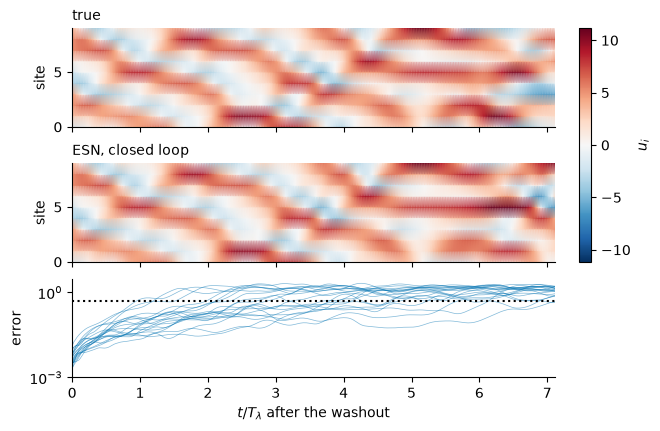

median valid time: 3.3 Lyapunov times


In [2]:
esn, data = model_esn(Lorenz96, CONFIG['truth'], CONFIG['forecast']['esn'])
t_lyap, N_lyap, i_test = data['t_lyap'], data['N_lyap'], data['i_test']
clean, noisy = data['clean_data'][i_test:], data['noisy_data'][i_test:]
t = data['t'][i_test:] - data['t'][i_test]
N_sites = clean.shape[1]

t_forecast = np.arange(300) * esn.dt_ESN / t_lyap
forecast, target, errors = washout_forecasts(esn, clean, clean, np.arange(20) * 8 * N_lyap, 300)
plot_washout(t_forecast, target, forecast, errors, space=True)
print(f'median valid time: {np.median(valid_times(errors, t_forecast)):.1f} Lyapunov times')

## 2. Every site observed: is inflation needed?

EnSRKF with 64 members, observations every 0.1 Lyapunov times, with the innovation-based inflation and without:

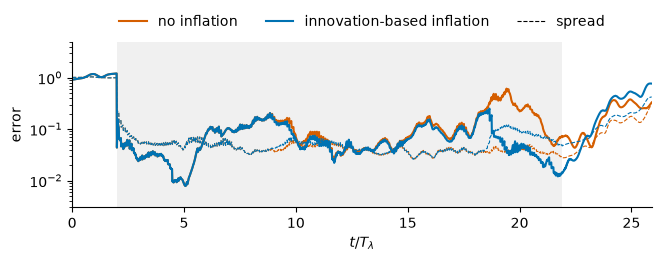

no inflation                 error 0.155, spread / error 0.28
innovation-based inflation   error 0.086, spread / error 0.65


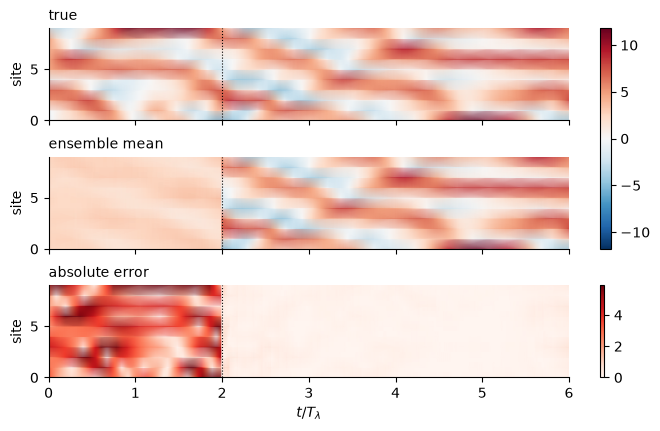

In [3]:
T_START, T_STOP, T_FORECAST = CONFIG['window_lyap']
FILTER = dict(m=DA['m'], da_method=DA['da_method'], cdd_fraction=DA['cdd_fraction'],
              **innovation_options(DA), t_extra=T_FORECAST * t_lyap)


def observe(n_sensors=N_sites, window=0):
    """Sensor sites (evenly spread on the ring) and their noisy observations."""
    sensors = measured_idx(n_sensors, N_sites, ring=True)
    return sensors, Observations(y_raw=noisy[:, sensors], y_true=clean[:, sensors], t_true=t, Nt_obs=DA['Nt_obs'],
                                 t_start=(T_START + 4 * window) * t_lyap, t_stop=(T_STOP + 4 * window) * t_lyap)


sensors, truth = observe()
run = deploy(esn, truth, measured=sensors, inflation='innovation', **FILTER)
run_1 = deploy(esn, truth, measured=sensors, inflation=1.0, **FILTER)
plot_errors({'no inflation': (run_1, VERMILLION), 'innovation-based inflation': (run, BLUE)}, truth, t, clean, t_lyap)
for label, r in [('no inflation', run_1), ('innovation-based inflation', run)]:
    s = state_metrics(r, truth, t, clean, t_lyap=t_lyap)
    print(f"{label:<28} error {s['rmse_mean_sync']:.3f}, spread / error {s['spread_skill']:.2f}")

w = run['t'] <= truth.t_obs[0] + 4 * t_lyap
u_true = clean[np.searchsorted(t, run['t'][w])]
plot_space_time({'true': u_true, 'ensemble mean': run['y'][w], 'absolute error': np.abs(run['y'][w] - u_true)},
                run['t'][w] / t_lyap, truth.t_obs[0] / t_lyap)

Without inflation, the ensemble is under-dispersed (spread about a quarter of the error) because of the model error of the network. The innovation-based inflation, 4 % on average, halves the error. On the Lorenz-63 system (tutorial 40), the same filter is over-dispersed and the inflation does not act: the factor must adapt to the case.

## 3. Sparse sensors

For the filter, only the observation operator changes. The substitution needs a network whose inputs are the measured sites, i.e. one network per sensor layout (`model_esn(..., measured=sensors, bayesian_update=False)`). Five windows each:

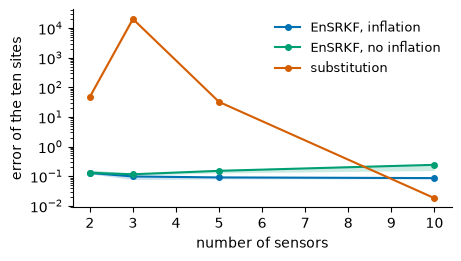

In [4]:
layouts = [10, 5, 3, 2]
sparse = np.zeros((3, len(layouts), 5, 1))
for i, n_sensors in enumerate(layouts):
    esn_sub, _ = model_esn(Lorenz96, CONFIG['truth'], CONFIG['forecast']['esn'],
                           measured=measured_idx(n_sensors, N_sites, ring=True), bayesian_update=False)
    for w in range(5):
        sensors, truth_w = observe(n_sensors, window=w)
        runs = [deploy(esn, truth_w, measured=sensors, inflation='innovation', **FILTER),
                deploy(esn, truth_w, measured=sensors, inflation=1.0, **FILTER),
                deploy(esn_sub, truth_w, measured=sensors, bayesian_update=False, t_extra=T_FORECAST * t_lyap)]
        sparse[:, i, w, 0] = [state_metrics(r, truth_w, t, clean, t_lyap=t_lyap)['rmse_mean_sync'] for r in runs]
plot_sweep(layouts, {'EnSRKF, inflation': (sparse[0], BLUE), 'EnSRKF, no inflation': (sparse[1], GREEN),
                     'substitution': (sparse[2], VERMILLION)}, 'number of sensors', ['error of the ten sites'])

- The substitution is the most accurate with every site measured, and fails with five sensors or fewer.
- The filter reconstructs the ten sites from two sensors with one network (median error 0.09 to 0.13).
- Inflation matters when the sensors are dense, which is when the ensemble is under-dispersed.

The 40-site system, with a localized filter, is in `scripts/esnda/run/run_parallel_localization.py`.